In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/student_data_cleaned.csv')

print("Shape:", df.shape)
df[['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Exam_Score']].describe().round(2)

Matplotlib is building the font cache; this may take a moment.


Shape: (6607, 20)


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,7.03,75.07,1.49,67.24
std,5.99,11.55,1.47,14.40,1.23,3.89
min,1.00,60.00,4.00,50.00,0.00,55.00
25%,16.00,70.00,6.00,63.00,1.00,65.00
50%,20.00,80.00,7.00,75.00,1.00,67.00
75%,24.00,90.00,8.00,88.00,2.00,69.00
max,44.00,100.00,10.00,100.00,8.00,100.00


Attendance           0.581
Hours_Studied        0.446
Previous_Scores      0.175
Tutoring_Sessions    0.156
Physical_Activity    0.028
Sleep_Hours         -0.017
Name: Exam_Score, dtype: float64


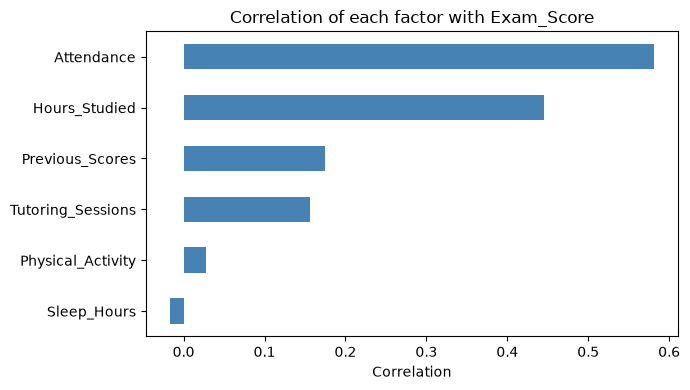

In [2]:
corr = df.select_dtypes('number').corr()['Exam_Score'].drop('Exam_Score').sort_values(ascending=False)
print(corr.round(3))

plt.figure(figsize=(7, 4))
corr.plot(kind='barh', color='steelblue')
plt.title('Correlation of each factor with Exam_Score')
plt.xlabel('Correlation')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

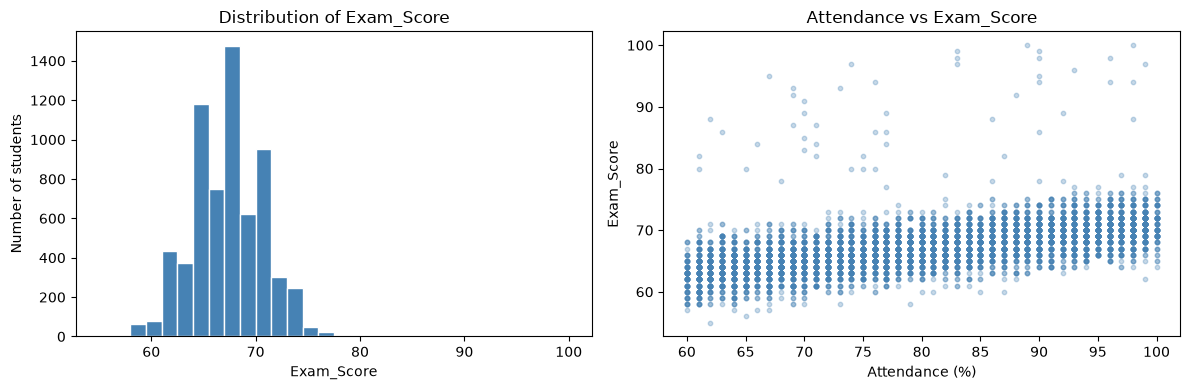

Mean: 67.24
Median: 67.0
Skewness: 1.64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['Exam_Score'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Exam_Score')
axes[0].set_xlabel('Exam_Score')
axes[0].set_ylabel('Number of students')

axes[1].scatter(df['Attendance'], df['Exam_Score'], alpha=0.3, s=10, color='steelblue')
axes[1].set_title('Attendance vs Exam_Score')
axes[1].set_xlabel('Attendance (%)')
axes[1].set_ylabel('Exam_Score')

plt.tight_layout()
plt.show()

print("Mean:", round(df['Exam_Score'].mean(), 2))
print("Median:", df['Exam_Score'].median())
print("Skewness:", round(df['Exam_Score'].skew(), 2))

Hours_Studied: 43 outliers (valid range 4.0 to 36.0)
Attendance: 0 outliers (valid range 40.0 to 120.0)
Sleep_Hours: 0 outliers (valid range 3.0 to 11.0)
Previous_Scores: 0 outliers (valid range 25.5 to 125.5)
Tutoring_Sessions: 430 outliers (valid range -0.5 to 3.5)
Exam_Score: 104 outliers (valid range 59.0 to 75.0)


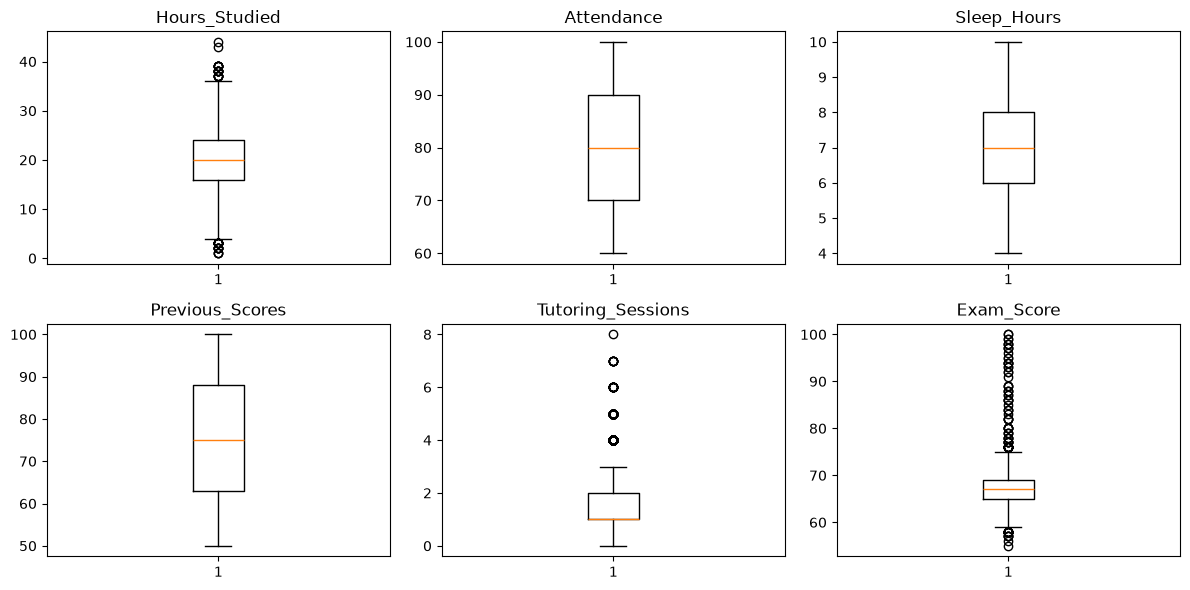

In [4]:
cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Exam_Score']

for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers (valid range {low:.1f} to {high:.1f})")

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flatten(), cols):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

Parental_Involvement {'High': 68.09, 'Low': 66.36, 'Medium': 67.1}
Access_to_Resources {'High': 68.09, 'Low': 66.2, 'Medium': 67.13}
Motivation_Level {'High': 67.7, 'Low': 66.75, 'Medium': 67.33}
Family_Income {'High': 67.84, 'Low': 66.85, 'Medium': 67.33}
Peer_Influence {'Negative': 66.56, 'Neutral': 67.2, 'Positive': 67.62}
Internet_Access {'No': 66.53, 'Yes': 67.29}


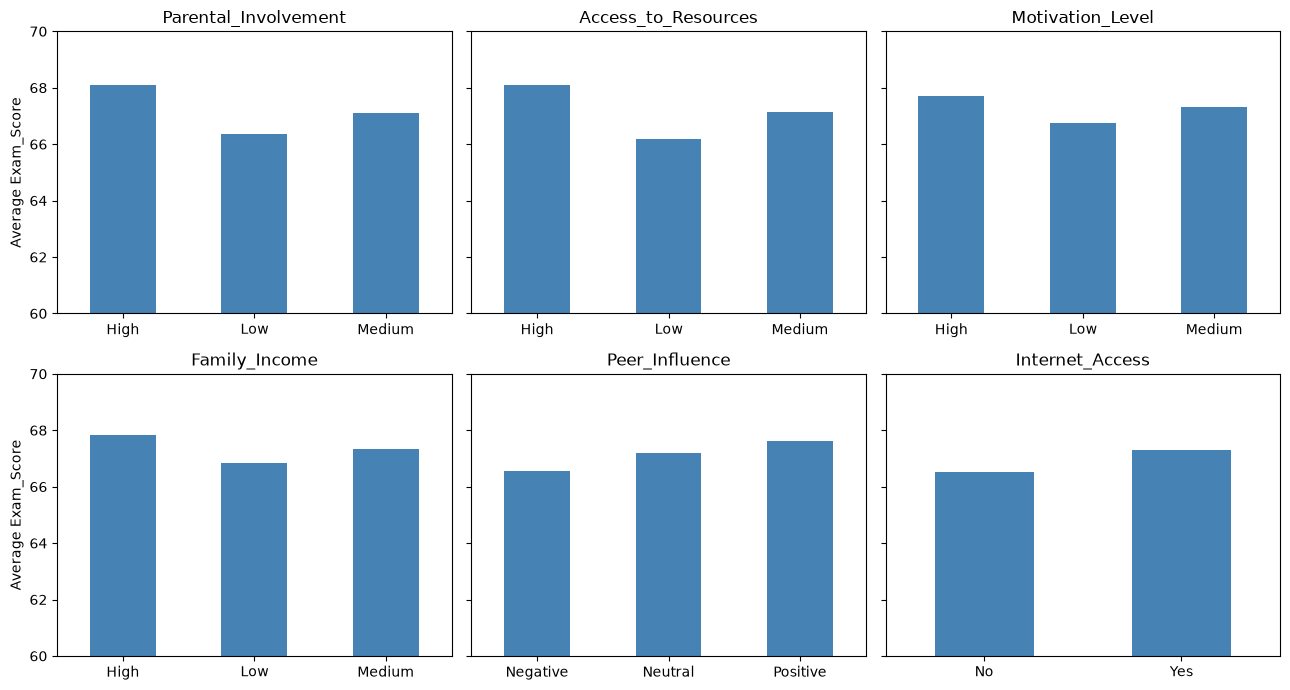

In [5]:
cat_cols = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
            'Family_Income', 'Peer_Influence', 'Internet_Access']

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, col in zip(axes.flatten(), cat_cols):
    means = df.groupby(col)['Exam_Score'].mean().round(2)
    print(col, means.to_dict())
    means.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_ylim(60, 70)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
axes[0, 0].set_ylabel('Average Exam_Score')
axes[1, 0].set_ylabel('Average Exam_Score')
plt.tight_layout()
plt.show()

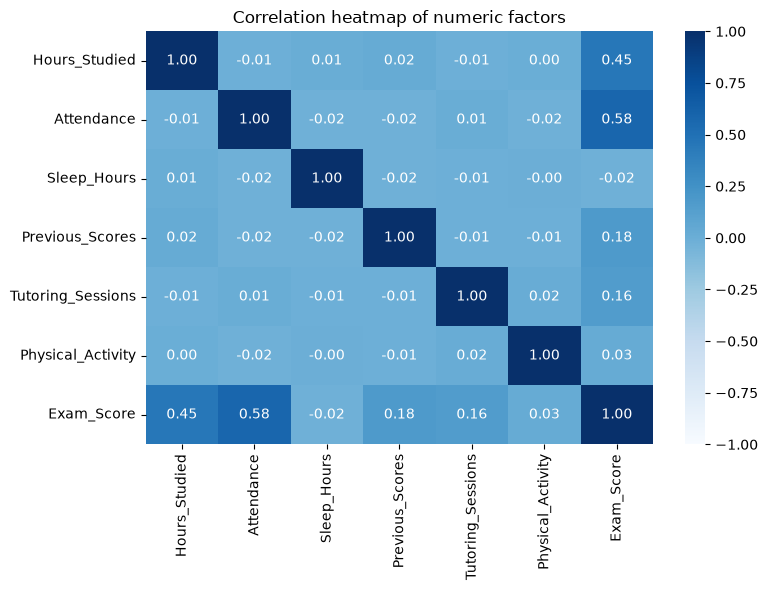

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1)
plt.title('Correlation heatmap of numeric factors')
plt.tight_layout()
plt.show()